# 17 - Model comparison

Is (calibrated) logistic regression actually the right model, or would a
different algorithm do better on the same inputs?

Every model below is scored with the **same walk-forward backtest** as
`src/backtest.py` / notebook 16: for each season from 22-23 to 25-26, train
only on the seasons before it, predict that season, then pool all four test
seasons (1,520 matches).

Two feature sets of interest (plus Dixon-Coles on its own for reference):

- **Original 3** - `EloDiff`, `XGDDiffLast5`, `GoalsPerGameDiff` (the deployed model)
- **Original 3 + DC** - those plus the 11 Dixon-Coles features

**Log loss is the main metric** - it scores the probabilities, which is what
the bets and the website use. Accuracy is shown too but is noisy (a 1-point
accuracy gap is ~15 matches). Ranked probability score (RPS), the standard
football metric that respects the A < D < H ordering, is included as a
second opinion.

Note: "linear regression" in the strict sense predicts a number, not a
class - the deployed model is *logistic* regression, which is the linear
model for H/D/A classification, so that's the baseline here.

In [1]:
import sys
sys.path.append("../src")

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, log_loss

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from predict_next_matches import (
    build_elo_feature,
    build_goals_per_game_feature,
    build_xgd_last5_feature,
)
from dixon_coles import build_dixon_coles_feature, DC_FEATURES

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)

## Data and features

In [2]:
matches = pd.read_csv("../data/processed/all_matches.csv")
matches["MatchDateTime"] = pd.to_datetime(matches["MatchDateTime"])
matches = matches.sort_values(["MatchDateTime", "HomeTeam", "AwayTeam"]).reset_index(drop=True)

# The three deployed features
build_elo_feature(matches)
build_goals_per_game_feature(matches)
build_xgd_last5_feature(matches)

# Dixon-Coles, refit once per gameweek on everything before it (~10-15s)
build_dixon_coles_feature(matches)

matches["Season"].value_counts().sort_index()

Season
21-22    380
22-23    380
23-24    380
24-25    380
25-26    380
26-27     70
Name: count, dtype: int64

In [3]:
original_features = ["EloDiff", "XGDDiffLast5", "GoalsPerGameDiff"]

feature_sets = {
    "Original 3": original_features,
    "Original 3 + DC": original_features + DC_FEATURES,
    "DC only": DC_FEATURES,
}

# Integer labels so every library (XGBoost in particular) is happy.
# Ordered A < D < H, which the RPS metric below relies on.
LABELS = ["A", "D", "H"]
matches["y"] = matches["FTR"].map({label: i for i, label in enumerate(LABELS)})

seasons = sorted(matches["Season"].unique())
min_season_matches = 200  # 26-27 is still in progress - too small to backtest

test_seasons = [
    season for season in seasons[1:]
    if (matches["Season"] == season).sum() >= min_season_matches
]
test_seasons

['22-23', '23-24', '24-25', '25-26']

## Metrics

- **Log loss** - lower is better. A model that always says the base rates
  (~44% H / 23% D / 33% A) scores about 1.07.
- **RPS** - ranked probability score, lower is better. Penalises a home-win
  prediction less for a draw than for an away win.
- **Brier** - mean squared error of the probability vector, lower is better.

In [4]:
def rps(y_true, proba):
    """Mean ranked probability score for ordered outcomes A < D < H."""
    outcome = np.eye(proba.shape[1])[y_true]
    cum_diff = np.cumsum(proba, axis=1) - np.cumsum(outcome, axis=1)
    return np.mean(np.sum(cum_diff[:, :-1] ** 2, axis=1) / (proba.shape[1] - 1))


def brier(y_true, proba):
    outcome = np.eye(proba.shape[1])[y_true]
    return np.mean(np.sum((proba - outcome) ** 2, axis=1))


def per_match_log_loss(y_true, proba):
    return -np.log(np.clip(proba[np.arange(len(y_true)), y_true], 1e-15, 1))


def score(y_true, proba):
    y_true = np.asarray(y_true)
    return {
        "LogLoss": log_loss(y_true, proba, labels=[0, 1, 2]),
        "RPS": rps(y_true, proba),
        "Brier": brier(y_true, proba),
        "Accuracy": accuracy_score(y_true, proba.argmax(axis=1)),
        "Draws predicted": int((proba.argmax(axis=1) == 1).sum()),
    }

## Bookmaker benchmark

Pinnacle's closing odds (falling back to the market average), with the
margin removed. This is the realistic ceiling: the market is very hard to
beat, so how close a model gets to this line matters more than its raw
accuracy.

In [5]:
def implied_probabilities(frame):
    odds = frame[["PSCA", "PSCD", "PSCH"]].to_numpy(dtype=float)
    fallback = frame[["AvgCA", "AvgCD", "AvgCH"]].to_numpy(dtype=float)
    odds = np.where(np.isnan(odds), fallback, odds)
    raw = 1 / odds
    return raw / raw.sum(axis=1, keepdims=True)  # strip the bookmaker margin


test_mask = matches["Season"].isin(test_seasons)
bookmaker_proba = implied_probabilities(matches[test_mask])

print("Matches missing odds:", np.isnan(bookmaker_proba).any(axis=1).sum())
bookmaker_scores = score(matches.loc[test_mask, "y"], bookmaker_proba)
bookmaker_scores

Matches missing odds: 0


{'LogLoss': 0.9604980366326752,
 'RPS': np.float64(0.19479678475673237),
 'Brier': np.float64(0.5703331200531839),
 'Accuracy': 0.5453947368421053,
 'Draws predicted': 0}

## The models

Hyperparameters are deliberately conservative (shallow trees, plenty of
regularisation): there are only ~380-1,500 training rows per fold and the
signal in football results is weak, so flexible models overfit quickly.
They are *not* tuned on the test seasons - that would flatter them (there's
a sensitivity check further down instead).

Every model is run two ways:

- **raw** - its own `predict_proba`
- **calibrated** - wrapped in `CalibratedClassifierCV(method="sigmoid", cv=5)`,
  exactly like the deployed model

`LogReg (deployed)` is a carbon copy of `train_model()` in
`predict_next_matches.py`.

In [6]:
scaled = lambda clf: make_pipeline(StandardScaler(), clf)

models = {
    "Base rates (no features)": DummyClassifier(strategy="prior"),
    "LogReg (deployed)": LogisticRegression(max_iter=2000, random_state=42),
    "LogReg scaled": scaled(LogisticRegression(max_iter=2000, random_state=42)),
    "LogReg scaled, strong L2": scaled(LogisticRegression(C=0.05, max_iter=2000, random_state=42)),
    "LDA": LinearDiscriminantAnalysis(),
    "Naive Bayes": GaussianNB(),
    "KNN (k=75)": scaled(KNeighborsClassifier(n_neighbors=75)),
    "SVM (RBF)": scaled(SVC(C=0.5, probability=True, random_state=42)),
    "Decision tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=40, random_state=42),
    "Random forest": RandomForestClassifier(
        n_estimators=500, max_depth=6, min_samples_leaf=20,
        max_features="sqrt", n_jobs=-1, random_state=42,
    ),
    "Extra trees": ExtraTreesClassifier(
        n_estimators=500, max_depth=6, min_samples_leaf=20,
        max_features="sqrt", n_jobs=-1, random_state=42,
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        learning_rate=0.03, max_iter=200, max_depth=3, min_samples_leaf=40,
        l2_regularization=1.0, random_state=42,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.02, max_depth=2, min_child_weight=10,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0,
        objective="multi:softprob", eval_metric="mlogloss",
        n_jobs=-1, random_state=42,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300, learning_rate=0.02, num_leaves=4, min_child_samples=40,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
        n_jobs=-1, random_state=42, verbose=-1,
    ),
    "Neural net (MLP)": scaled(MLPClassifier(
        hidden_layer_sizes=(16,), alpha=1.0, max_iter=2000,
        early_stopping=True, random_state=42,
    )),
}

In [7]:
def walk_forward(estimator, features, calibrate):
    """Pooled out-of-sample probabilities over every test season."""

    pooled_proba, pooled_true, pooled_season = [], [], []

    for season in test_seasons:

        index = seasons.index(season)
        train = matches[matches["Season"].isin(seasons[:index])]
        test = matches[matches["Season"] == season]

        model = clone(estimator)
        if calibrate:
            model = CalibratedClassifierCV(estimator=model, method="sigmoid", cv=5)

        model.fit(train[features], train["y"])

        pooled_proba.append(model.predict_proba(test[features]))
        pooled_true.append(test["y"].to_numpy())
        pooled_season.append(test["Season"].to_numpy())

    return {
        "proba": np.vstack(pooled_proba),
        "true": np.concatenate(pooled_true),
        "season": np.concatenate(pooled_season),
    }

In [8]:
# ~10 minutes: 15 models x 3 feature sets x raw/calibrated x 4 seasons
results = {}
rows = []

for set_name, features in feature_sets.items():
    for model_name, estimator in models.items():
        for calibrate in [False, True]:

            start = time.time()
            out = walk_forward(estimator, features, calibrate)
            key = (model_name, set_name, "calibrated" if calibrate else "raw")
            results[key] = out

            rows.append({
                "Model": model_name,
                "Features": set_name,
                "Version": key[2],
                **score(out["true"], out["proba"]),
                "Seconds": round(time.time() - start, 1),
            })

comparison = pd.DataFrame(rows)

# Same matches in the same order for every model - checked once here
y_test = results[("LogReg (deployed)", "Original 3", "calibrated")]["true"]
assert all((out["true"] == y_test).all() for out in results.values())
assert (y_test == matches.loc[test_mask, "y"].to_numpy()).all()

## Results

In [9]:
# Best version (raw or calibrated) of every model, per feature set, by log loss
best_version = (
    comparison
    .sort_values("LogLoss")
    .groupby(["Model", "Features"], as_index=False)
    .first()
)

leaderboard = best_version.pivot(index="Model", columns="Features", values="LogLoss")
leaderboard = leaderboard[list(feature_sets)].sort_values("Original 3 + DC")
leaderboard.loc["Bookmaker (Pinnacle close)"] = bookmaker_scores["LogLoss"]

print("Pooled log loss, 1,520 matches (lower is better)")
leaderboard.style.format("{:.4f}").highlight_min(axis=0, subset=pd.IndexSlice[leaderboard.index[:-1], :])

Pooled log loss, 1,520 matches (lower is better)


Features,Original 3,Original 3 + DC,DC only
Model,,,
"LogReg scaled, strong L2",0.9805,0.9789,0.9921
LogReg (deployed),0.9805,0.9791,0.9925
LDA,0.9804,0.9824,0.9953
LogReg scaled,0.9805,0.9838,0.9984
Extra trees,0.9842,0.9852,0.9947
Random forest,0.9929,0.9877,1.0022
XGBoost,0.9946,0.9888,1.0038
KNN (k=75),0.9891,0.9905,1.0007
LightGBM,0.9991,0.9933,1.0076


In [10]:
# Full table - every model, feature set and version
comparison.sort_values("LogLoss").reset_index(drop=True)

,Model,Features,Version,LogLoss,RPS,Brier,Accuracy,Draws predicted,Seconds
0,"LogReg scaled, strong L2",Original 3 + DC,calibrated,0.9789,0.2000,0.5825,0.5388,0,0.3
1,"LogReg scaled, strong L2",Original 3 + DC,raw,0.9790,0.2002,0.5832,0.5408,1,0.1
2,LogReg (deployed),Original 3 + DC,calibrated,0.9791,0.2000,0.5825,0.5421,0,7.0
3,LogReg (deployed),Original 3 + DC,raw,0.9796,0.2001,0.5831,0.5421,2,1.7
4,LDA,Original 3,calibrated,0.9804,0.2009,0.5844,0.5434,0,0.3
...,...,...,...,...,...,...,...,...,...
85,Decision tree,Original 3 + DC,raw,1.0962,0.2127,0.6129,0.5316,0,0.0
86,Naive Bayes,Original 3,raw,1.1101,0.2216,0.6337,0.5342,8,0.0
87,Neural net (MLP),DC only,raw,1.1672,0.2330,0.6965,0.4033,619,0.4
88,Naive Bayes,DC only,raw,1.6223,0.2516,0.7201,0.4888,350,0.0


In [11]:
# Raw vs calibrated - does wrapping in CalibratedClassifierCV help each model?
calibration_effect = comparison.pivot_table(
    index="Model", columns=["Features", "Version"], values="LogLoss"
)
calibration_effect

Features                    DC only         Original 3          \
Version                  calibrated     raw calibrated     raw   
Model                                                            
Base rates (no features)     1.0689  1.0689     1.0689  1.0689   
Decision tree                1.0128  1.0402     0.9985  1.0726   
Extra trees                  0.9947  1.0000     0.9842  1.0243   
HistGradientBoosting         1.0184  1.0501     1.0033  1.0338   
KNN (k=75)                   1.0007  1.0071     0.9891  0.9917   
LDA                          0.9989  0.9953     0.9804  0.9814   
LightGBM                     1.0076  1.0212     0.9991  1.0097   
LogReg (deployed)            0.9949  0.9925     0.9805  0.9815   
LogReg scaled                0.9988  0.9984     0.9805  0.9814   
LogReg scaled, strong L2     0.9942  0.9921     0.9808  0.9805   
Naive Bayes                  1.0022  1.6223     0.9885  1.1101   
Neural net (MLP)             1.0186  1.1672     0.9955  1.0205   
Random forest                1.0028  1.0022     0.9929  0.9954   
SVM (RBF)                    1.0105  1.0183     0.9972  0.9986   
XGBoost                      1.0038  1.0090     0.9946  0.9986   

Features                 Original 3 + DC          
Version                       calibrated     raw  
Model                                             
Base rates (no features)          1.0689  1.0689  
Decision tree                     1.0028  1.0962  
Extra trees                       0.9852  0.9927  
HistGradientBoosting              1.0029  1.0339  
KNN (k=75)                        0.9905  0.9959  
LDA                               0.9824  0.9832  
LightGBM                          0.9933  1.0049  
LogReg (deployed)                 0.9791  0.9796  
LogReg scaled                     0.9838  0.9846  
LogReg scaled, strong L2          0.9789  0.9790  
Naive Bayes                       0.9975  2.0339  
Neural net (MLP)                  1.0055  1.0479  
Random forest                     0.9877  0.9883  
SVM (RBF)                         1.0107  0.9990  
XGBoost                           0.9888  0.9920

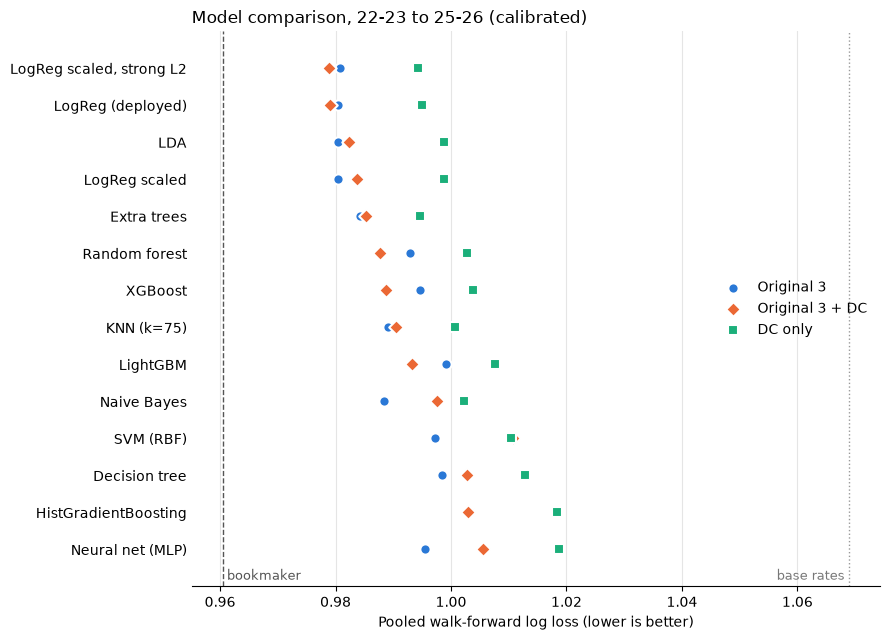

In [12]:
# Log loss by model, one dot per feature set (calibrated versions), with the
# base-rate and bookmaker reference lines. Shorter = better.
plot_models = [m for m in leaderboard.index if m in models and m != "Base rates (no features)"]
calibrated_ll = comparison[comparison["Version"] == "calibrated"].pivot(
    index="Model", columns="Features", values="LogLoss"
).loc[plot_models]

colors = {"Original 3": "#2a78d6", "Original 3 + DC": "#eb6834", "DC only": "#1baf7a"}
markers = {"Original 3": "o", "Original 3 + DC": "D", "DC only": "s"}

fig, ax = plt.subplots(figsize=(9, 6.5))
y_pos = np.arange(len(plot_models))[::-1]

for set_name in feature_sets:
    ax.scatter(
        calibrated_ll[set_name], y_pos, s=55, color=colors[set_name],
        marker=markers[set_name], edgecolor="white", linewidth=1.5,
        label=set_name, zorder=3,
    )

base_rate_ll = comparison.loc[comparison["Model"] == "Base rates (no features)", "LogLoss"].min()
ax.axvline(bookmaker_scores["LogLoss"], color="#555", linestyle="--", linewidth=1)
ax.text(bookmaker_scores["LogLoss"], -0.9, " bookmaker", color="#555", va="bottom", fontsize=9)
ax.axvline(base_rate_ll, color="#999", linestyle=":", linewidth=1)
ax.text(base_rate_ll, -0.9, "base rates ", color="#777", va="bottom", ha="right", fontsize=9)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_models)
ax.set_xlabel("Pooled walk-forward log loss (lower is better)")
ax.set_title("Model comparison, 22-23 to 25-26 (calibrated)", loc="left")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_ylim(-1, len(plot_models))
ax.legend(frameon=False, loc="center right")
plt.tight_layout()
plt.show()

## Are the differences real?

Differences of 0.002-0.005 in log loss are easily noise over 1,520 matches.
A paired bootstrap of the per-match log loss difference vs the deployed
model gives a 95% interval: if it straddles 0, there's no evidence the
model is better or worse.

In [13]:
rng = np.random.default_rng(42)
n_boot = 5000
boot_index = rng.integers(0, len(y_test), size=(n_boot, len(y_test)))

reference = results[("LogReg (deployed)", "Original 3", "calibrated")]
reference_losses = per_match_log_loss(y_test, reference["proba"])

significance = []

for _, row in best_version.iterrows():

    out = results[(row["Model"], row["Features"], row["Version"])]
    diff = per_match_log_loss(y_test, out["proba"]) - reference_losses
    boot = diff[boot_index].mean(axis=1)
    low, high = np.percentile(boot, [2.5, 97.5])

    significance.append({
        "Model": row["Model"],
        "Features": row["Features"],
        "Version": row["Version"],
        "LogLoss": row["LogLoss"],
        "Accuracy": row["Accuracy"],
        "Diff vs deployed": diff.mean(),
        "95% CI low": low,
        "95% CI high": high,
        "P(better than deployed)": (boot < 0).mean(),
    })

significance = pd.DataFrame(significance).sort_values("LogLoss").reset_index(drop=True)
significance.head(20)

,Model,Features,Version,LogLoss,Accuracy,Diff vs deployed,95% CI low,95% CI high,P(better than deployed)
0,"LogReg scaled, strong L2",Original 3 + DC,calibrated,0.9789,0.5388,-1.5956e-03,-0.0069,0.0036,0.7274
1,LogReg (deployed),Original 3 + DC,calibrated,0.9791,0.5421,-1.3525e-03,-0.0065,0.0037,0.7054
2,LDA,Original 3,calibrated,0.9804,0.5434,-4.6858e-05,-0.0016,0.0015,0.5140
3,LogReg (deployed),Original 3,calibrated,0.9805,0.5434,0.0000e+00,0.0000,0.0000,0.0000
4,LogReg scaled,Original 3,calibrated,0.9805,0.5428,1.8378e-05,-0.0001,0.0002,0.3994
5,"LogReg scaled, strong L2",Original 3,raw,0.9805,0.5428,7.5946e-05,-0.0030,0.0033,0.4708
6,LDA,Original 3 + DC,calibrated,0.9824,0.5421,1.9080e-03,-0.0045,0.0083,0.2822
7,LogReg scaled,Original 3 + DC,calibrated,0.9838,0.5408,3.2981e-03,-0.0034,0.0098,0.1658
8,Extra trees,Original 3,calibrated,0.9842,0.5421,3.7649e-03,-0.0011,0.0087,0.0662
9,Extra trees,Original 3 + DC,calibrated,0.9852,0.5283,4.7321e-03,-0.0042,0.0137,0.1474


## Consistency across seasons

A model that wins on the pooled number by being great in one season and
poor in the others is less trustworthy than one that's steadily good.

In [14]:
top_keys = [
    tuple(r) for r in significance[["Model", "Features", "Version"]].head(8).to_numpy()
]
if ("LogReg (deployed)", "Original 3", "calibrated") not in top_keys:
    top_keys.append(("LogReg (deployed)", "Original 3", "calibrated"))

per_season = []
for key in top_keys:
    out = results[key]
    row = {"Model": f"{key[0]} | {key[1]} | {key[2]}"}
    for season in test_seasons:
        mask = out["season"] == season
        row[season] = log_loss(out["true"][mask], out["proba"][mask], labels=[0, 1, 2])
    per_season.append(row)

bookmaker_row = {"Model": "Bookmaker (Pinnacle close)"}
season_array = matches.loc[test_mask, "Season"].to_numpy()
for season in test_seasons:
    mask = season_array == season
    bookmaker_row[season] = log_loss(y_test[mask], bookmaker_proba[mask], labels=[0, 1, 2])
per_season.append(bookmaker_row)

per_season = pd.DataFrame(per_season).set_index("Model")
per_season["Wins vs deployed"] = (
    per_season[test_seasons]
    .lt(per_season.loc["LogReg (deployed) | Original 3 | calibrated", test_seasons])
    .sum(axis=1)
)
per_season

,22-23,23-24,24-25,25-26,Wins vs deployed
Model,,,,,
"LogReg scaled, strong L2 | Original 3 + DC | calibrated",0.9712,0.9354,0.9802,1.0287,3
LogReg (deployed) | Original 3 + DC | calibrated,0.9698,0.9389,0.9789,1.0289,2
LDA | Original 3 | calibrated,0.9687,0.9389,0.9844,1.0297,2
LogReg (deployed) | Original 3 | calibrated,0.9693,0.9388,0.9830,1.0308,0
LogReg scaled | Original 3 | calibrated,0.9694,0.9387,0.9830,1.0308,2
"LogReg scaled, strong L2 | Original 3 | raw",0.9720,0.9344,0.9853,1.0304,2
LDA | Original 3 + DC | calibrated,0.9767,0.9465,0.9791,1.0272,2
LogReg scaled | Original 3 + DC | calibrated,0.9806,0.9461,0.9786,1.0297,2
Bookmaker (Pinnacle close),0.9622,0.8995,0.9664,1.0139,4


## Calibration of the leading models

When the model says 60%, does that happen ~60% of the time? Checked for the
home-win probability (the class with the most data).

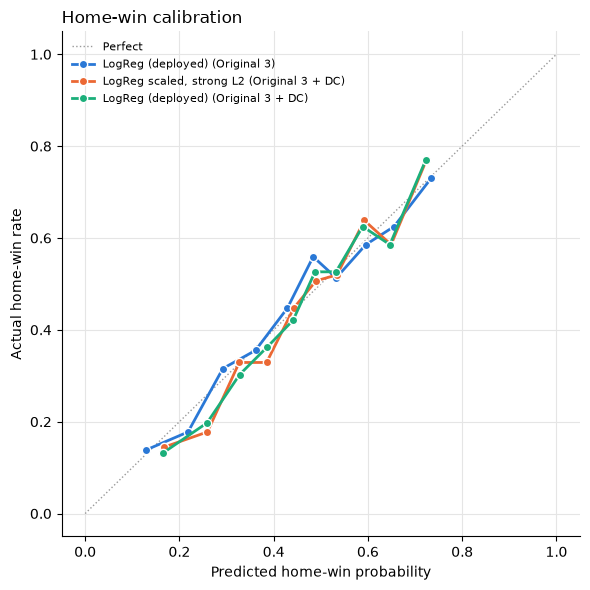

In [15]:
calibration_keys = [("LogReg (deployed)", "Original 3", "calibrated")] + [
    key for key in top_keys[:3] if key != ("LogReg (deployed)", "Original 3", "calibrated")
][:2]

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color="#999", linestyle=":", linewidth=1, label="Perfect")

for key, color in zip(calibration_keys, ["#2a78d6", "#eb6834", "#1baf7a"]):
    out = results[key]
    frac, mean_pred = calibration_curve(out["true"] == 2, out["proba"][:, 2], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", color=color, linewidth=2, markersize=6,
            markeredgecolor="white", label=f"{key[0]} ({key[1]})")

ax.set_xlabel("Predicted home-win probability")
ax.set_ylabel("Actual home-win rate")
ax.set_title("Home-win calibration", loc="left")
ax.grid(color="#e5e5e5", linewidth=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## Which features do the tree models actually use?

Permutation importance on the latest test season (25-26), with the models
trained on 21-22 to 24-25: how much log loss worsens when each feature is
shuffled. Near-zero or negative = the model gets nothing from it.

In [16]:
importance_features = feature_sets["Original 3 + DC"]
train = matches[matches["Season"].isin(seasons[:seasons.index("25-26")])]
test = matches[matches["Season"] == "25-26"]

importances = {}
for name in ["LogReg scaled", "Random forest", "XGBoost"]:
    model = clone(models[name]).fit(train[importance_features], train["y"])
    result = permutation_importance(
        model, test[importance_features], test["y"],
        scoring="neg_log_loss", n_repeats=30, random_state=42, n_jobs=-1,
    )
    importances[name] = result.importances_mean

pd.DataFrame(importances, index=importance_features).sort_values("XGBoost", ascending=False)

,LogReg scaled,Random forest,XGBoost
EloDiff,0.0484,0.0124,2.6031e-02
XGDDiffLast5,0.0094,0.0017,7.4537e-03
DCAttackHome,-0.0014,-0.0003,3.5737e-03
DCDefenseAway,0.0073,0.0009,2.7947e-03
DCDrawProb,0.0009,-0.0007,7.4360e-04
DCAttackAway,0.0028,-0.0012,1.1998e-04
DCHomeProb,0.0076,-0.0004,4.1548e-05
DCLambda,0.0038,-0.0016,-1.4011e-05
GoalsPerGameDiff,-0.0004,-0.0011,-2.3650e-04
DCDefenseHome,-0.0016,0.0001,-2.8617e-04


## Sensitivity: would tuning rescue the tree models?

A small grid over the settings that matter most for XGBoost and random
forest. **Caveat:** picking the best cell of this grid uses the test
seasons, so the best number here is optimistic - it's an upper bound on
what tuning could buy, not a fair score.

In [17]:
tuning_rows = []

for set_name in ["Original 3", "Original 3 + DC"]:
    features = feature_sets[set_name]

    for depth in [1, 2, 3, 5]:
        for n_estimators in [150, 400]:
            estimator = clone(models["XGBoost"]).set_params(max_depth=depth, n_estimators=n_estimators)
            out = walk_forward(estimator, features, calibrate=False)
            tuning_rows.append({
                "Model": "XGBoost", "Features": set_name,
                "Setting": f"depth={depth}, trees={n_estimators}",
                **score(out["true"], out["proba"]),
            })

    for depth in [3, 6, None]:
        for leaf in [10, 40, 100]:
            estimator = clone(models["Random forest"]).set_params(max_depth=depth, min_samples_leaf=leaf)
            out = walk_forward(estimator, features, calibrate=False)
            tuning_rows.append({
                "Model": "Random forest", "Features": set_name,
                "Setting": f"depth={depth}, leaf={leaf}",
                **score(out["true"], out["proba"]),
            })

tuning = pd.DataFrame(tuning_rows)
tuning.sort_values("LogLoss").groupby(["Model", "Features"]).head(3)

,Model,Features,Setting,LogLoss,RPS,Brier,Accuracy,Draws predicted
26,Random forest,Original 3 + DC,"depth=3, leaf=40",0.9820,0.2018,0.5851,0.5309,0
32,Random forest,Original 3 + DC,"depth=None, leaf=40",0.9829,0.2018,0.5857,0.5283,0
29,Random forest,Original 3 + DC,"depth=6, leaf=40",0.9829,0.2018,0.5857,0.5296,0
18,XGBoost,Original 3 + DC,"depth=1, trees=400",0.9857,0.2023,0.5876,0.5408,7
19,XGBoost,Original 3 + DC,"depth=2, trees=150",0.9877,0.2031,0.5886,0.5368,1
17,XGBoost,Original 3 + DC,"depth=1, trees=150",0.9890,0.2033,0.5891,0.5375,0
9,Random forest,Original 3,"depth=3, leaf=40",0.9905,0.2039,0.5908,0.5395,0
12,Random forest,Original 3,"depth=6, leaf=40",0.9913,0.2041,0.5915,0.5362,0
15,Random forest,Original 3,"depth=None, leaf=40",0.9916,0.2042,0.5917,0.5368,0
2,XGBoost,Original 3,"depth=2, trees=150",0.9937,0.2046,0.5926,0.5408,2


## Simple ensemble

Averaging a linear model with a tree model sometimes beats both, because
they make different mistakes.

In [18]:
def ensemble_of(keys):
    return np.mean([results[key]["proba"] for key in keys], axis=0)


ensembles = {
    "LogReg + XGBoost (Original 3)": [
        ("LogReg (deployed)", "Original 3", "calibrated"),
        ("XGBoost", "Original 3", "raw"),
    ],
    "LogReg + XGBoost (Original 3 + DC)": [
        ("LogReg scaled", "Original 3 + DC", "calibrated"),
        ("XGBoost", "Original 3 + DC", "raw"),
    ],
    "LogReg + RF + XGBoost (Original 3 + DC)": [
        ("LogReg scaled", "Original 3 + DC", "calibrated"),
        ("Random forest", "Original 3 + DC", "raw"),
        ("XGBoost", "Original 3 + DC", "raw"),
    ],
}

ensemble_rows = []
for name, keys in ensembles.items():
    proba = ensemble_of(keys)
    diff = per_match_log_loss(y_test, proba) - reference_losses
    boot = diff[boot_index].mean(axis=1)
    ensemble_rows.append({
        "Ensemble": name, **score(y_test, proba),
        "Diff vs deployed": diff.mean(),
        "P(better than deployed)": (boot < 0).mean(),
    })

pd.DataFrame(ensemble_rows)

,Ensemble,LogLoss,RPS,Brier,Accuracy,Draws predicted,Diff vs deployed,P(better than deployed)
0,LogReg + XGBoost (Original 3),0.9853,0.2026,0.5879,0.5401,1,0.0048,0.0182
1,LogReg + XGBoost (Original 3 + DC),0.9831,0.2017,0.5858,0.5428,1,0.0026,0.2284
2,LogReg + RF + XGBoost (Original 3 + DC),0.9835,0.2020,0.5863,0.5401,1,0.0031,0.1968


## Conclusion

**Logistic regression is the right model.** The top six places all go to
linear models (logistic regression variants and LDA), sitting around
0.979-0.981 log loss. Every non-linear model does worse with the same
inputs:

| | Best log loss | vs deployed |
|---|---|---|
| LogReg, Original 3 (deployed) | 0.9805 | - |
| LogReg, Original 3 + DC | 0.9791 | -0.0014 (95% CI -0.0065 to +0.0037) |
| Extra trees | 0.9842 | +0.004 |
| Random forest | 0.9877 | +0.007 |
| XGBoost | 0.9888 | +0.008 |
| LightGBM | 0.9933 | +0.013 |
| SVM / HistGB / MLP / single tree | 0.997-1.003 | +0.017 to +0.022 |
| Bookmaker (Pinnacle close) | 0.9605 | -0.020 |
| Base rates, no features | 1.0689 | +0.088 |

Several of the tree/boosting models are measurably worse (bootstrap 95%
interval clear of zero), and even the *optimistically* tuned random forest
and XGBoost from the sensitivity grid (0.982 / 0.986, tuned on the test
seasons themselves) still don't beat plain logistic regression. With a few
thousand matches and a weak, roughly linear signal (a bigger Elo/xG gap
means steadily higher home-win odds), the flexibility of trees buys
nothing but variance.

**Dixon-Coles features: a small, unproven gain.** Adding the 11 DC
features to logistic regression improves log loss by ~0.0014 - about a 70%
chance it's a real improvement, but the interval comfortably includes zero
and it beats the 3-feature model in only 2 of 4 seasons (3 of 4 with strong
L2 regularisation). DC helps the tree models more, but only because they
start further behind. DC *on its own* is clearly worse than the original 3.
The permutation importances show why: `EloDiff` carries most of the
signal, `XGDDiffLast5` is a distant second, and the DC columns mostly
repeat what Elo already says. This matches notebook 16's finding.

**Other notes**

- Sigmoid calibration makes almost no difference to logistic regression
  (it's already well calibrated - see the calibration plot) but helps the
  tree models a lot.
- Averaging logistic regression with XGBoost / random forest doesn't beat
  logistic regression alone.
- No model ever predicts a draw - expected, since a draw is almost never
  the single most likely outcome.
- The remaining gap is to the bookmaker (~0.02 log loss, ~0.5 pts of
  accuracy), not between algorithms. Closing it means **better inputs**
  (team news, rest days, schedule congestion, xG-based ratings), not a
  fancier model.

**Recommendation:** keep the deployed calibrated logistic regression.
Switching to Original 3 + DC with strong L2 (`C=0.05`, scaled) is a
defensible marginal upgrade, but the evidence for it is weak and it adds a
Dixon-Coles fit to every weekly run - worth re-checking once 26-27 is
complete and there's a fifth test season.